In [1]:
%% MIT 18.03 Lecture 29: Laplace Transform IV, Pole Diagram & t-Shift Rule
% Description: Demonstrates Pole Diagrams and Time-Delay properties via Control System Toolbox:
%              1) 3D Surface of |F(s)| ("Three-pole circus": poles at 0 and -1 +/- 2i).
%              2) Dominant pole behavior for f(t) = 1 + e^{-t}sin(2t).
%              3) t-Shift Rule (Transport Delay e^{-as}) using tf 'InputDelay' property.
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, impulse, pole, pzplot).
%
% % MBD Concept Mapping: Visualizes s-plane poles as 3D magnitude singularities,
% %                      validates dominant rightmost pole asymptotics, and models
% %                      pure transport delay e^{-as} in LTI systems.


clear; clc; close all;


%% =========================================================================
%% Part 1: 3D Pole Surface ("Circus Tent") & Dominant Poles (Sections [3]-[4])
%% =========================================================================
% Lecture Example 3: f(t) = 1 + e^{-t}*sin(2t)
% F(s) = 1/s + 2 / ((s + 1)^2 + 4) = 1/s + 2 / (s^2 + 2s + 5)
% Poles at s = 0 (Rightmost dominant pole) and s = -1 +/- 2i (Damped oscillatory poles)
s = tf('s');
F_osc  = 2 / (s^2 + 2*s + 5);
F_step = 1 / s;
F_total = F_step + F_osc;


sys_poles = pole(F_total);
roc_boundary = max(real(sys_poles)); % Rightmost pole Re(s) = 0


fprintf('=== MIT 18.03 Lecture 29 Pole Diagram Diagnostics ===\n');

=== MIT 18.03 Lecture 29 Pole Diagram Diagnostics ===

In [2]:
fprintf('Combined Signal F(s) = 1/s + 2/(s^2 + 2s + 5)\n');

Combined Signal F(s) = 1/s + 2/(s^2 + 2s + 5)

In [3]:
fprintf('Extracted Poles:\n');

Extracted Poles:

In [4]:
for idx = 1:length(sys_poles)
    fprintf('  Pole %d: %+.4f %+.4fi\n', idx, real(sys_poles(idx)), imag(sys_poles(idx)));
end

  Pole 1: +0.0000 +0.0000i
  Pole 2: -1.0000 +2.0000i
  Pole 3: -1.0000 -2.0000i

In [5]:
fprintf('Rightmost Dominant Pole Re(s) : %.4f (Defines ROC: Re(s) > %.2f)\n', ...
        roc_boundary, roc_boundary);

Rightmost Dominant Pole Re(s) : 0.0000 (Defines ROC: Re(s) > 0.00)

In [6]:
fprintf('=====================================================\n\n');


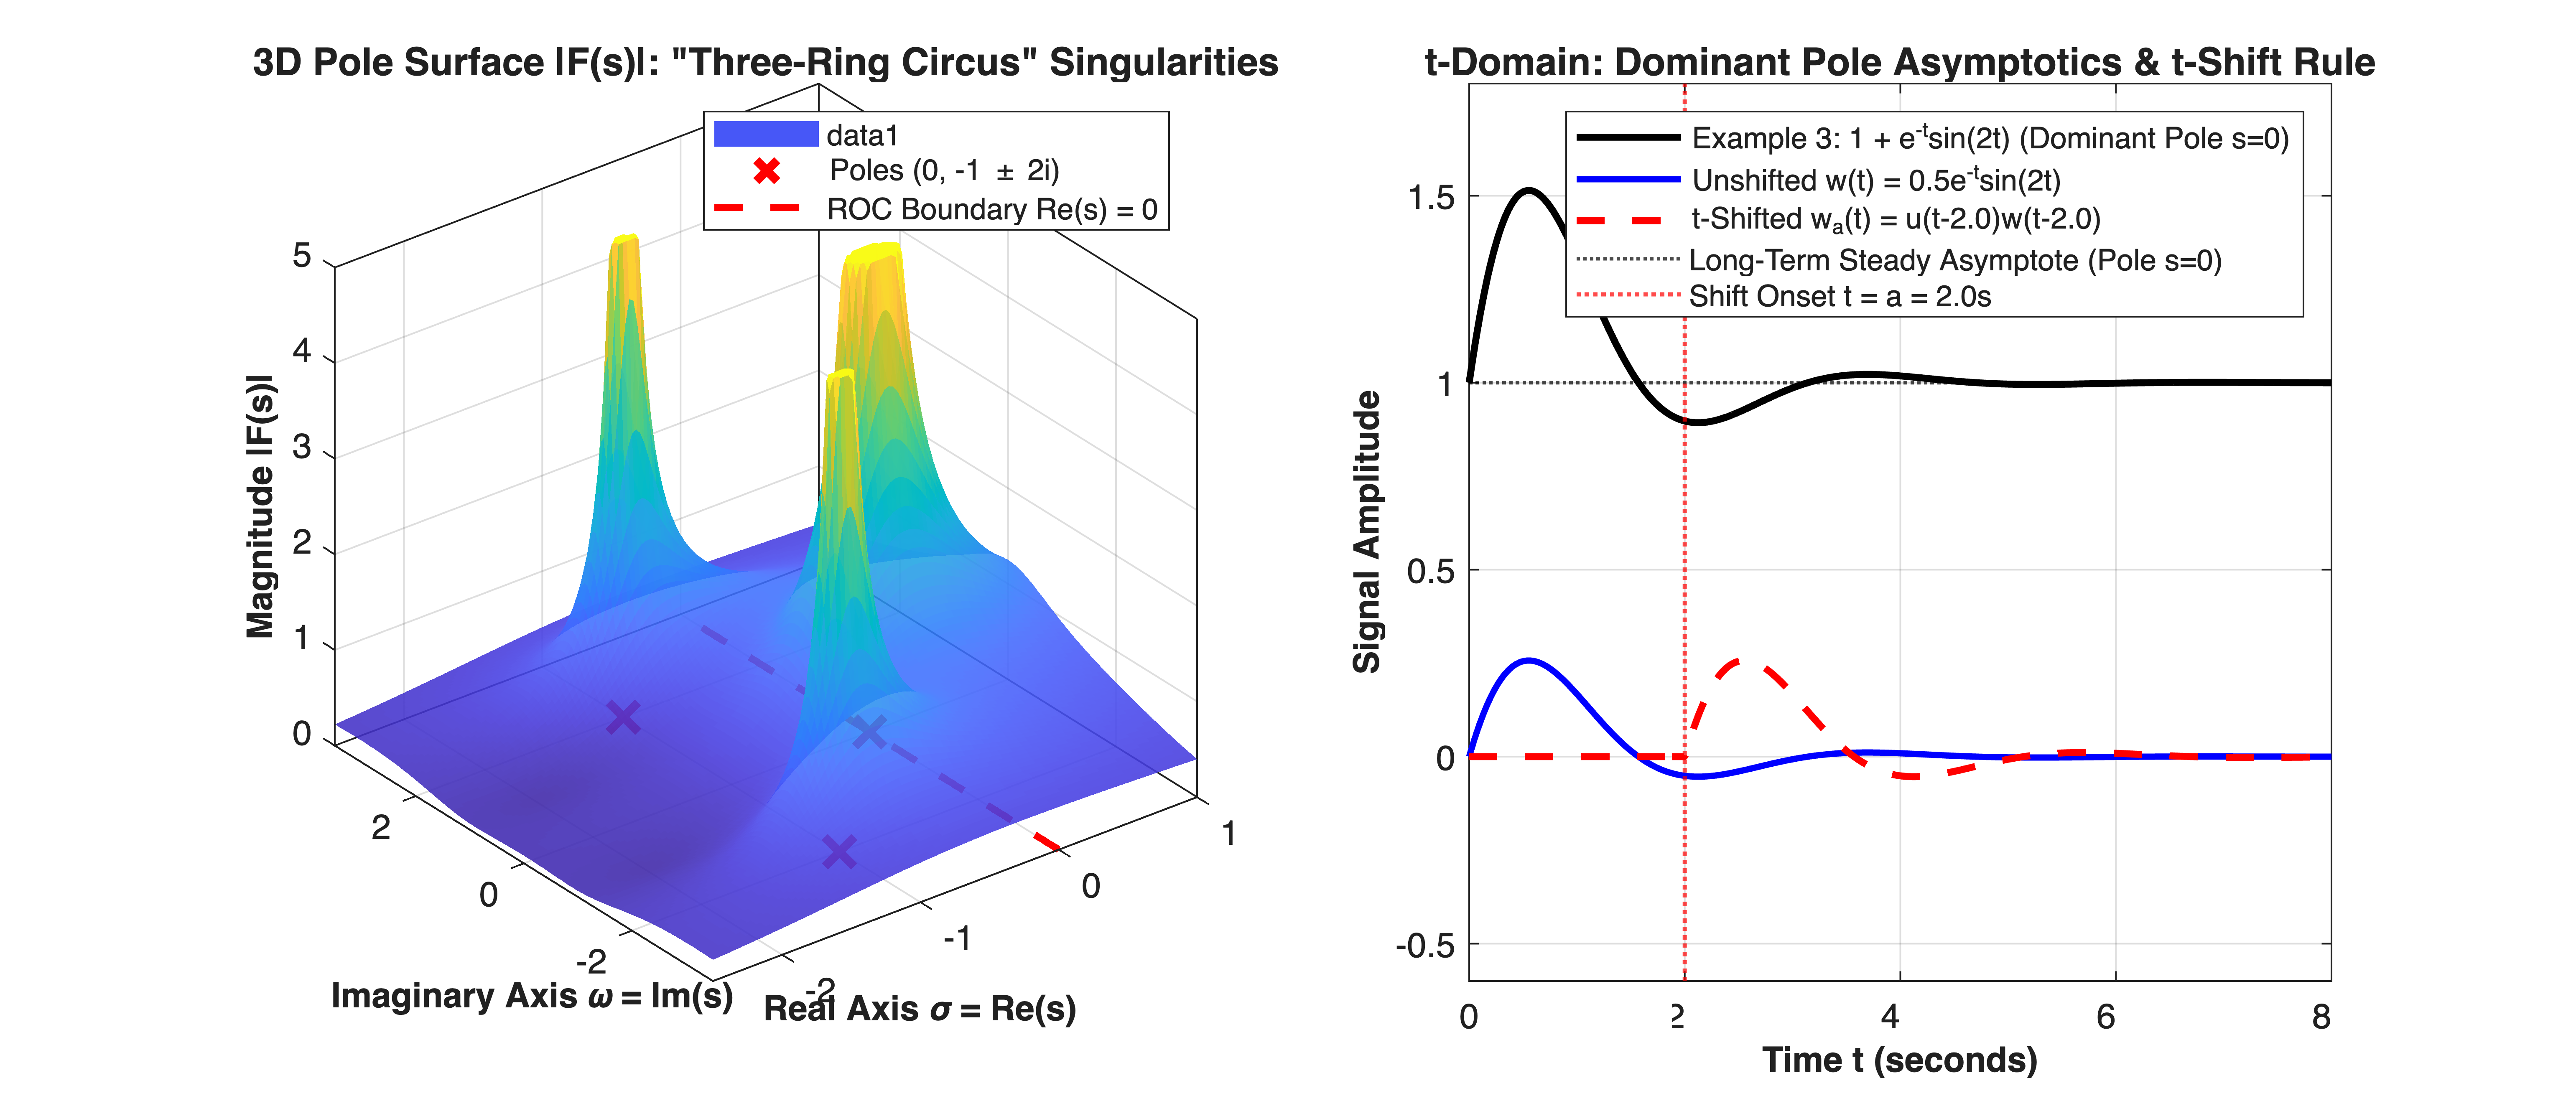

In [7]:


% Create complex grid s = sigma + j*omega for 3D surface plot
sigma_vec = linspace(-2.5, 1.0, 120);
omega_vec = linspace(-3.5, 3.5, 140);
[Sigma, Omega] = meshgrid(sigma_vec, omega_vec);
S_grid = Sigma + 1i * Omega;


% Evaluate |F(s)| on the complex plane (cap peak at 5.0 for clean visualization)
F_mag = abs(1 ./ S_grid + 2 ./ ((S_grid + 1).^2 + 4));
F_mag_capped = min(F_mag, 5.0);


figure('Color', [1 1 1], 'Position', [80, 80, 1200, 520]);


% Subplot 1: 3D Surface of |F(s)| over the Complex s-Plane
subplot(1, 2, 1);
surf(Sigma, Omega, F_mag_capped, 'EdgeColor', 'none', 'FaceAlpha', 0.88);
hold on; grid on; box on;
colormap(parula);


% Plot the 3 pole locations at the base plane z = 0
plot3(real(sys_poles), imag(sys_poles), zeros(size(sys_poles)), 'rx', ...
      'MarkerSize', 12, 'LineWidth', 2.5, 'DisplayName', 'Poles (0, -1 \pm 2i)');


% Highlight the ROC boundary line at Re(s) = 0
plot3(zeros(size(omega_vec)), omega_vec, zeros(size(omega_vec)), 'r--', ...
      'LineWidth', 2.0, 'DisplayName', 'ROC Boundary Re(s) = 0');


xlabel('Real Axis \sigma = Re(s)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Imaginary Axis \omega = Im(s)', 'FontSize', 10, 'FontWeight', 'bold');
zlabel('Magnitude |F(s)|', 'FontSize', 10, 'FontWeight', 'bold');
title('3D Pole Surface |F(s)|: "Three-Ring Circus" Singularities', ...
      'FontSize', 11, 'FontWeight', 'bold');
view([-38, 32]);
xlim([-2.5, 1.0]); ylim([-3.5, 3.5]); zlim([0, 5.0]);
legend('Location', 'northeast', 'FontSize', 8.5);


%% =========================================================================
%% Part 2: The t-Shift Rule (Transport Delay e^{-as}) via Control Toolbox
%% =========================================================================
% Unshifted signal: f(t) = (1/2)*e^{-t}*sin(2t)  <--->  F(s) = 1 / (s^2 + 2s + 5)
% Shifted signal:   f_a(t) = u(t - a)*f(t - a)   <--->  e^{-a*s} * F(s)
delay_a = 2.0; % Time shift a = 2.0 seconds


W_unshifted = tf(1, [1, 2, 5]);
W_shifted   = tf(1, [1, 2, 5], 'InputDelay', delay_a); % Models e^{-2s} * W(s)


t_eval = linspace(0, 8.0, 1000);
[y_unshifted, ~] = impulse(W_unshifted, t_eval);
[y_shifted, ~]   = impulse(W_shifted,   t_eval);
[y_combined, ~]  = impulse(F_total,     t_eval);


% Subplot 2: Time-Domain Dominant Behavior & t-Shift Delay
subplot(1, 2, 2);
hold on; grid on; box on;


plot(t_eval, y_combined, 'k-', 'LineWidth', 2.0, ...
     'DisplayName', 'Example 3: 1 + e^{-t}sin(2t) (Dominant Pole s=0)');
plot(t_eval, y_unshifted, 'b-', 'LineWidth', 1.8, ...
     'DisplayName', 'Unshifted w(t) = 0.5e^{-t}sin(2t)');
plot(t_eval, y_shifted, 'r--', 'LineWidth', 2.0, ...
     'DisplayName', sprintf('t-Shifted w_a(t) = u(t-%.1f)w(t-%.1f)', delay_a, delay_a));


yline(1.0, 'k:', 'LineWidth', 1.0, 'DisplayName', 'Long-Term Steady Asymptote (Pole s=0)');
xline(delay_a, 'r:', 'LineWidth', 1.2, 'DisplayName', sprintf('Shift Onset t = a = %.1fs', delay_a));


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Signal Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title('t-Domain: Dominant Pole Asymptotics & t-Shift Rule', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([0, 8.0]);
ylim([-0.6, 1.8]);